In [3]:
import os

print(os.getcwd())
print(os.listdir())

/home/e7901f35-bc05-4543-9b5c-f97283ca323e
['.local', 'archive (1).zip', 'mpu6050_abc_metadata.pkl', '.jupyter', 'live_predict.ipynb', '.pythonstartup.py', '.cache', '.ipython', 'Untitled.ipynb', 'lstm_air_writing.keras', 'untitled.py', 'README.ipynb', 'test_40.csv', 'mpu6050_abc_random_forest.pkl', 'TrainTestSplit.ipynb', 'live_test_raw_data.csv', '.vimrc', 'anaconda_projects', '.anaconda', 'Untitled Folder 1', '.conda', 'BuildTrainLSTM.ipynb', 'Untitled1.ipynb', 'label_encoder.pkl', '.npm', '.virtualenvs', '.gitconfig', 'RandomForestDataset.ipynb', '.ipynb_checkpoints', '.keras', 'untitled.md', 'train_60.csv', '.config', 'Untitled Folder', 'gestures_augmented.csv', 'lstm_scaler.pkl', '.profile', 'mpu6050_abc_model_files.zip', '.bashrc']


In [4]:
import pandas as pd

live_raw = pd.read_csv("live_test_raw_data.csv")

print("Shape:", live_raw.shape)
print()
print(live_raw.head())

Shape: (30, 604)

             timestamp actual  trial_number predicted  value_1  value_2  \
0  2026-09-03T22:35:57      A             1         A   2.7318  -7.9110   
1  2026-09-03T22:36:19      A             2         C   0.4561  -9.6325   
2  2026-09-03T22:36:41      A             3         A   3.8906  -5.2834   
3  2026-09-03T22:37:22      A             4         A   2.0985  -9.0124   
4  2026-09-03T22:38:01      A             5         A   2.8659  -6.1190   

   value_3  value_4  value_5  value_6  ...  value_591  value_592  value_593  \
0 -18.2570   0.0998  -0.0147  -0.0084  ...   -18.3599    -0.0195    -0.0325   
1 -18.1145   0.0039   0.0564  -0.0414  ...   -18.1983    -0.0361     0.1998   
2 -19.2302  -0.0003   0.4242  -0.1010  ...   -18.1852     0.0598     0.1266   
3 -18.5227  -0.5461   0.9180  -0.0077  ...   -18.4545    -0.0183    -0.0258   
4 -18.0271   0.8344  -0.0053  -0.5506  ...   -18.3252     0.0061     0.1158   

   value_594  value_595  value_596  value_597  value_598

In [5]:
print("Columns:", live_raw.columns.tolist())

print("\nSamples by actual class:")
print(live_raw["actual"].value_counts())

Columns: ['timestamp', 'actual', 'trial_number', 'predicted', 'value_1', 'value_2', 'value_3', 'value_4', 'value_5', 'value_6', 'value_7', 'value_8', 'value_9', 'value_10', 'value_11', 'value_12', 'value_13', 'value_14', 'value_15', 'value_16', 'value_17', 'value_18', 'value_19', 'value_20', 'value_21', 'value_22', 'value_23', 'value_24', 'value_25', 'value_26', 'value_27', 'value_28', 'value_29', 'value_30', 'value_31', 'value_32', 'value_33', 'value_34', 'value_35', 'value_36', 'value_37', 'value_38', 'value_39', 'value_40', 'value_41', 'value_42', 'value_43', 'value_44', 'value_45', 'value_46', 'value_47', 'value_48', 'value_49', 'value_50', 'value_51', 'value_52', 'value_53', 'value_54', 'value_55', 'value_56', 'value_57', 'value_58', 'value_59', 'value_60', 'value_61', 'value_62', 'value_63', 'value_64', 'value_65', 'value_66', 'value_67', 'value_68', 'value_69', 'value_70', 'value_71', 'value_72', 'value_73', 'value_74', 'value_75', 'value_76', 'value_77', 'value_78', 'value_79',

In [6]:
value_columns = [
    col for col in live_raw.columns
    if col.startswith("value_")
]

print("Number of sensor features:", len(value_columns))

Number of sensor features: 600


In [7]:
import joblib

metadata = joblib.load("mpu6050_abc_metadata.pkl")

print("Metadata type:", type(metadata))
print()
print("Metadata:")
print(metadata)

Metadata type: <class 'dict'>

Metadata:
{'classes': ['A', 'B', 'C'], 'samples_per_recording': 100, 'channels': 6, 'features': 600, 'sample_interval_ms': 40, 'channels_order': ['Accel X', 'Accel Y', 'Accel Z', 'Gyro X', 'Gyro Y', 'Gyro Z']}


In [8]:
import joblib

model = joblib.load("mpu6050_abc_random_forest.pkl")

print("Model:", type(model))
print("Classes:", model.classes_)
print("Number of input features:", model.n_features_in_)

if hasattr(model, "n_estimators"):
    print("Number of trees:", model.n_estimators)

if hasattr(model, "max_depth"):
    print("Max depth:", model.max_depth)

Model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Classes: ['A' 'B' 'C']
Number of input features: 600
Number of trees: 500
Max depth: None


In [9]:
mistakes = live_raw[
    live_raw["actual"] != live_raw["predicted"]
    ]

print("Number of mistakes:", len(mistakes))
print()

print(
    mistakes[
        ["timestamp", "actual", "trial_number", "predicted"]
        ]
)

Number of mistakes: 3

             timestamp actual  trial_number predicted
1  2026-09-03T22:36:19      A             2         C
7  2026-09-03T22:39:36      A             8         C
9  2026-09-03T22:40:46      A            10         C


In [10]:
X_live = live_raw[value_columns].astype(float)

pred_check = model.predict(X_live)
prob_check = model.predict_proba(X_live)

comparison = live_raw[
    ["actual", "trial_number", "predicted"]
    ].copy()

comparison["recalculated"] = pred_check
comparison["match"] = (
    comparison["predicted"] == comparison["recalculated"]
)

print(comparison)
print()
print(
    "Predictions reproduced:",
    comparison["match"].sum(),
    "/",
    len(comparison)
)

   actual  trial_number predicted recalculated  match
0       A             1         A            A   True
1       A             2         C            C   True
2       A             3         A            A   True
3       A             4         A            A   True
4       A             5         A            A   True
5       A             6         A            A   True
6       A             7         A            A   True
7       A             8         C            C   True
8       A             9         A            A   True
9       A            10         C            C   True
10      B             1         B            B   True
11      B             2         B            B   True
12      B             3         B            B   True
13      B             4         B            B   True
14      B             5         B            B   True
15      B             6         B            B   True
16      B             7         B            B   True
17      B             8     

/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


In [11]:
A_indices = live_raw["actual"] == "A"

A_analysis = live_raw.loc[
    A_indices,
    ["trial_number", "actual", "predicted"]
].copy()

A_probs = model.predict_proba(
    X_live.loc[A_indices]
)

class_to_index = {
    label: i
    for i, label in enumerate(model.classes_)
}

A_analysis["prob_A"] = A_probs[:, class_to_index["A"]]
A_analysis["prob_B"] = A_probs[:, class_to_index["B"]]
A_analysis["prob_C"] = A_probs[:, class_to_index["C"]]

A_analysis["confidence"] = A_probs.max(axis=1)

print(
    A_analysis.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

 trial_number actual predicted  prob_A  prob_B  prob_C  confidence
            1      A         A   0.636   0.072   0.292       0.636
            2      A         C   0.326   0.326   0.348       0.348
            3      A         A   0.682   0.070   0.248       0.682
            4      A         A   0.422   0.190   0.388       0.422
            5      A         A   0.644   0.080   0.276       0.644
            6      A         A   0.578   0.092   0.330       0.578
            7      A         A   0.558   0.086   0.356       0.558
            8      A         C   0.314   0.156   0.530       0.530
            9      A         A   0.538   0.100   0.362       0.538
           10      A         C   0.372   0.192   0.436       0.436


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


In [12]:
channels = metadata["channels_order"]
samples_per_recording = metadata["samples_per_recording"]

sensor_array = X_live.to_numpy().reshape(
    len(X_live),
    samples_per_recording,
    len(channels)
)

print("Sensor array shape:", sensor_array.shape)
print("Channels:", channels)

Sensor array shape: (30, 100, 6)
Channels: ['Accel X', 'Accel Y', 'Accel Z', 'Gyro X', 'Gyro Y', 'Gyro Z']


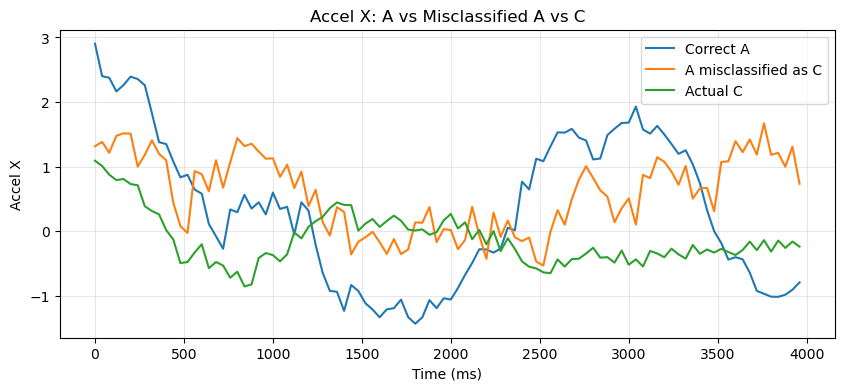

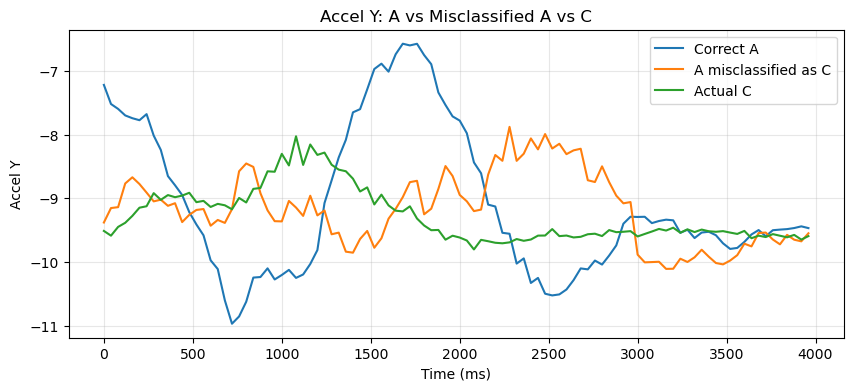

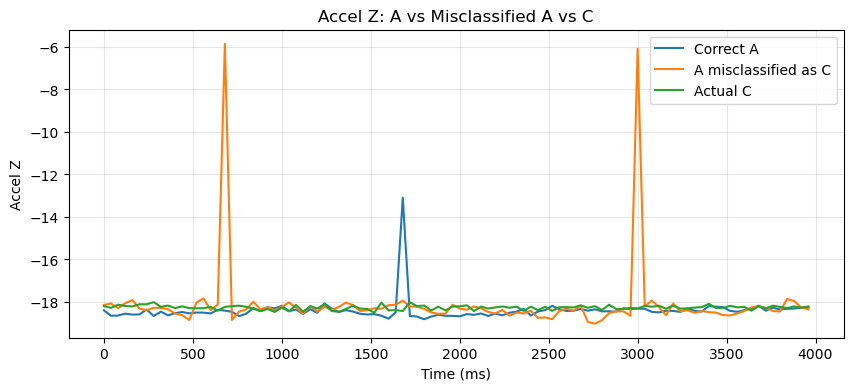

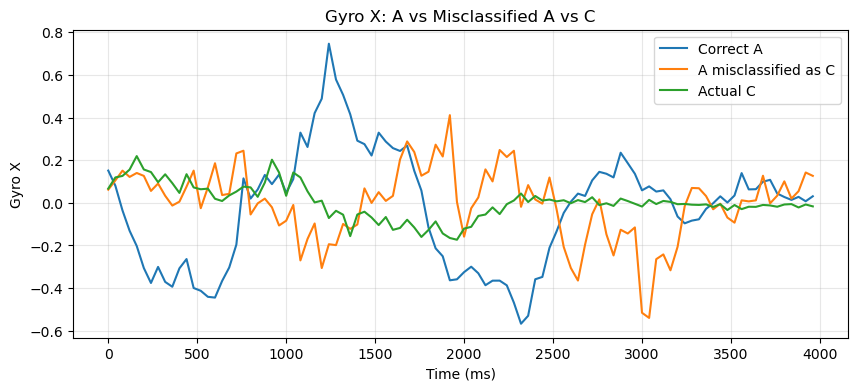

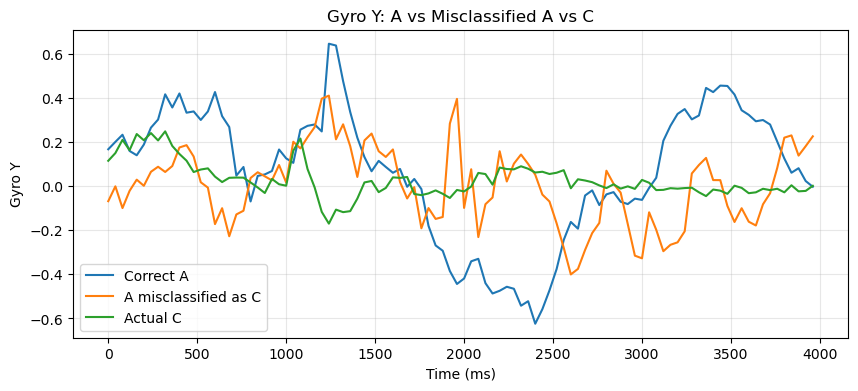

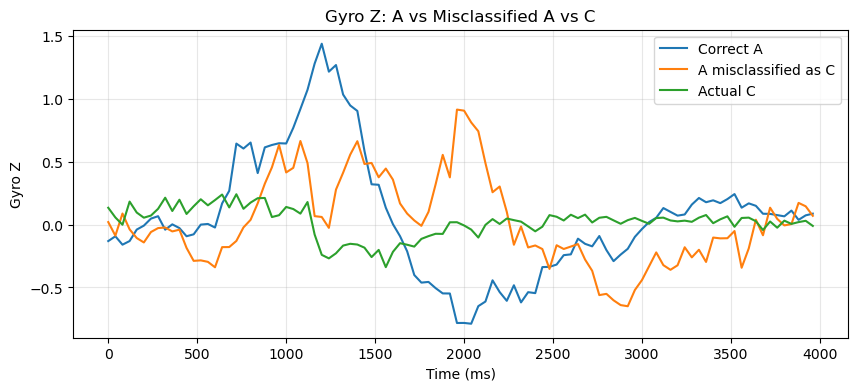

In [13]:
import matplotlib.pyplot as plt
import numpy as np

time_ms = (
    np.arange(samples_per_recording)
    * metadata["sample_interval_ms"]
)

A_correct_mask = (
    (live_raw["actual"] == "A") &
    (live_raw["predicted"] == "A")
)

A_wrong_mask = (
    (live_raw["actual"] == "A") &
    (live_raw["predicted"] == "C")
)

C_mask = live_raw["actual"] == "C"

A_correct_mean = sensor_array[A_correct_mask].mean(axis=0)
A_wrong_mean = sensor_array[A_wrong_mask].mean(axis=0)
C_mean = sensor_array[C_mask].mean(axis=0)

for channel_index, channel_name in enumerate(channels):

    plt.figure(figsize=(10, 4))

    plt.plot(
        time_ms,
        A_correct_mean[:, channel_index],
        label="Correct A"
    )

    plt.plot(
        time_ms,
        A_wrong_mean[:, channel_index],
        label="A misclassified as C"
    )

    plt.plot(
        time_ms,
        C_mean[:, channel_index],
        label="Actual C"
    )

    plt.xlabel("Time (ms)")
    plt.ylabel(channel_name)
    plt.title(f"{channel_name}: A vs Misclassified A vs C")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [14]:
rows = []

for i, channel in enumerate(channels):

    correct_A = sensor_array[A_correct_mask, :, i]
    wrong_A = sensor_array[A_wrong_mask, :, i]
    actual_C = sensor_array[C_mask, :, i]

    rows.append({
        "channel": channel,
        "correct_A_mean": correct_A.mean(),
        "wrong_A_mean": wrong_A.mean(),
        "C_mean": actual_C.mean(),

        "wrongA_to_correctA_distance":
            np.mean(np.abs(wrong_A.mean(axis = 0)
                           - correct_A.mean(axis = 0))),

        "wrongA_to_C_distance":
            np.mean(np.abs(wrong_A.mean(axis = 0)
                           - actual_C.mean(axis = 0)))
    })

channel_comparison = pd.DataFrame(rows)

print(
    channel_comparison.to_string(
        index = False,
        float_format = lambda x: f"{x:.4f}"
    )
)      

channel  correct_A_mean  wrong_A_mean   C_mean  wrongA_to_correctA_distance  wrongA_to_C_distance
Accel X          0.3376        0.5903  -0.1338                       0.9416                0.8322
Accel Y         -9.0839       -9.1693  -9.2757                       1.1151                0.6040
Accel Z        -18.4029      -18.1151 -18.2657                       0.5290                0.4635
 Gyro X         -0.0286       -0.0027   0.0030                       0.2995                0.1419
 Gyro Y          0.0670        0.0032   0.0290                       0.2639                0.1596
 Gyro Z          0.0607        0.0238   0.0199                       0.4034                0.3334


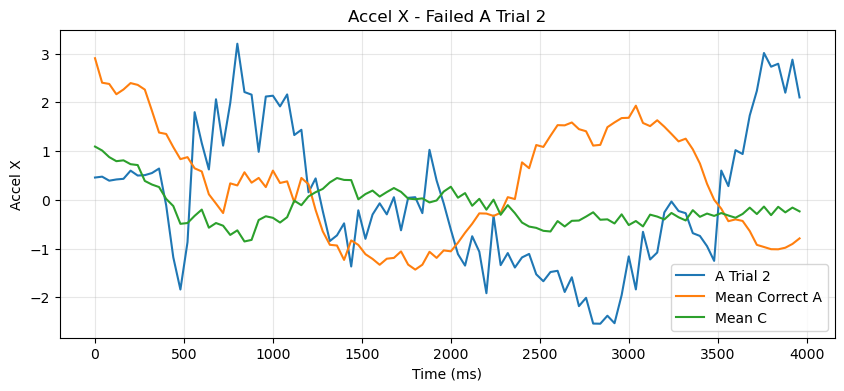

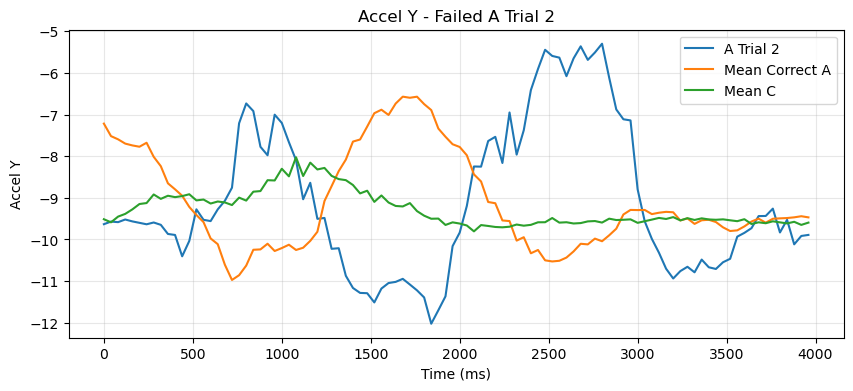

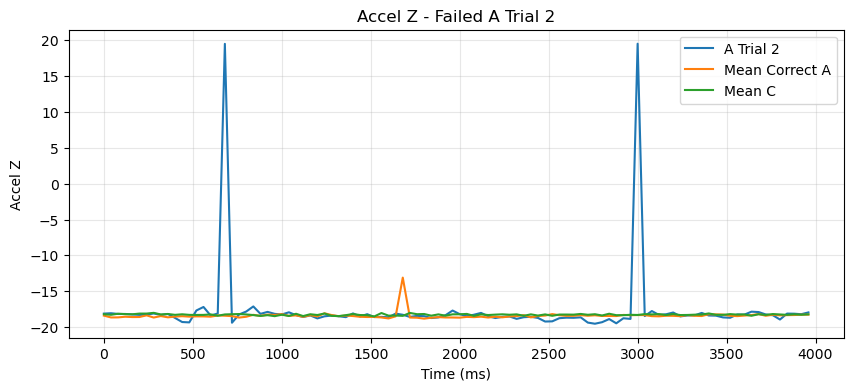

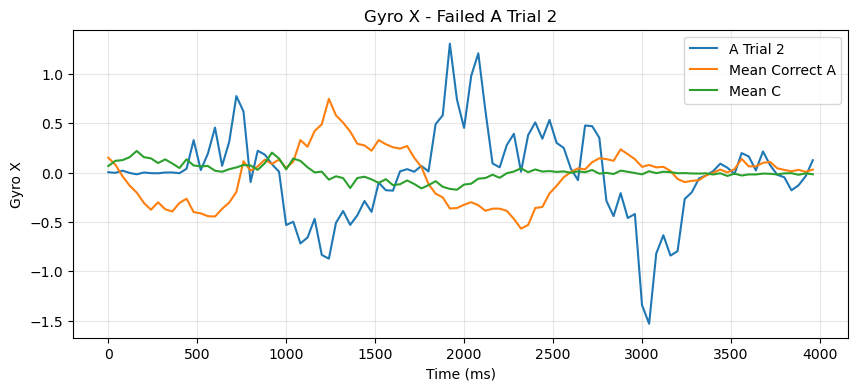

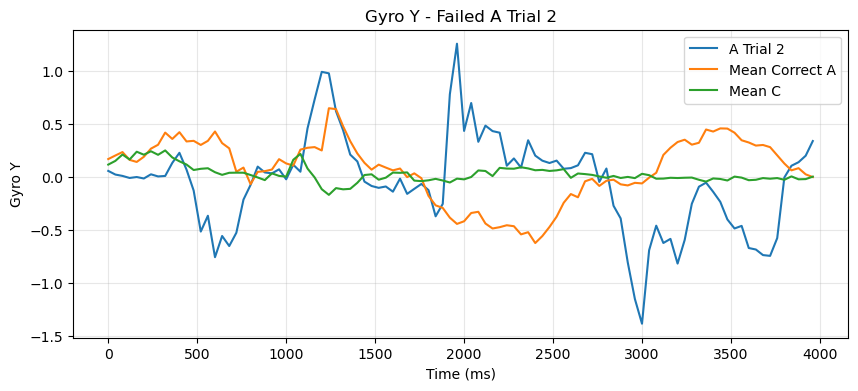

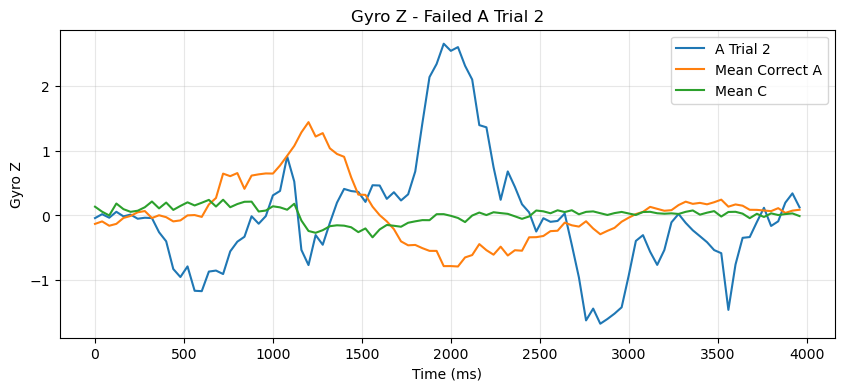

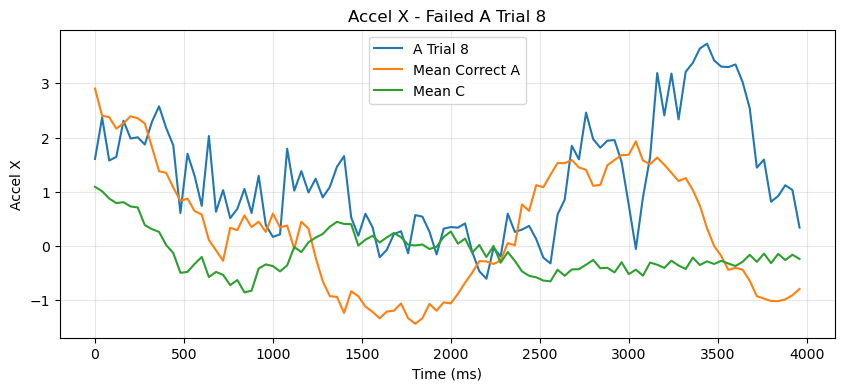

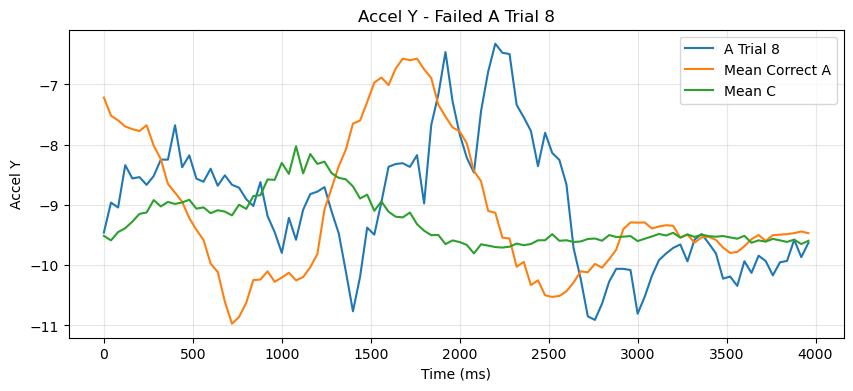

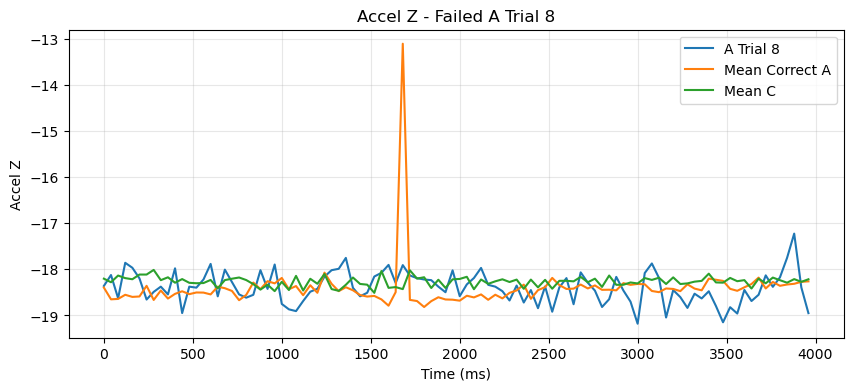

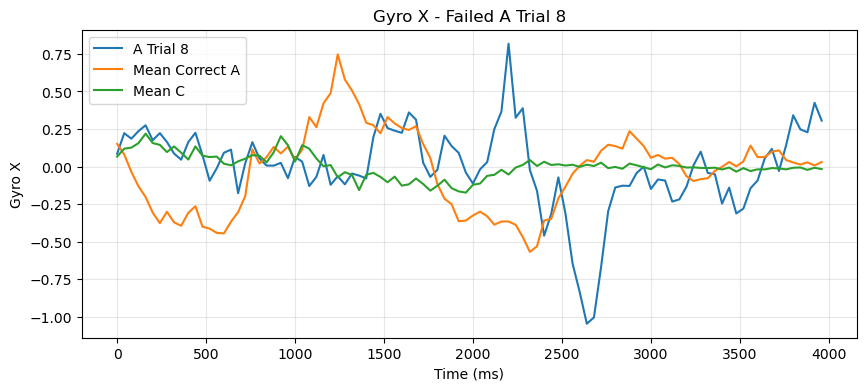

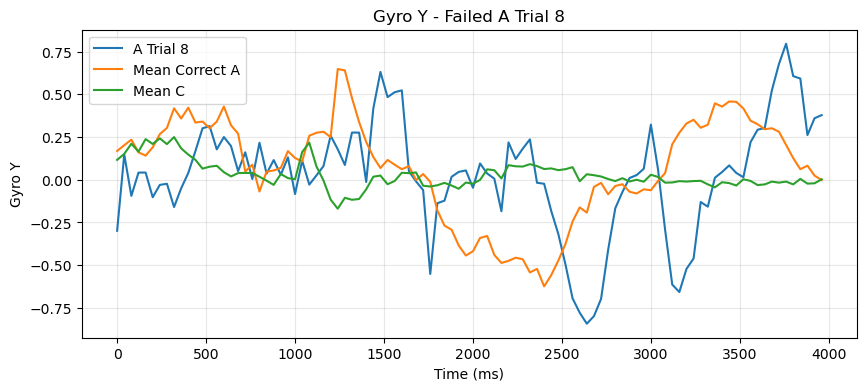

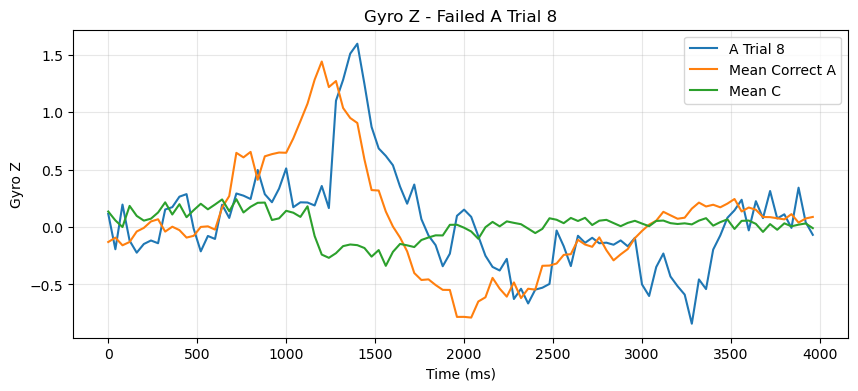

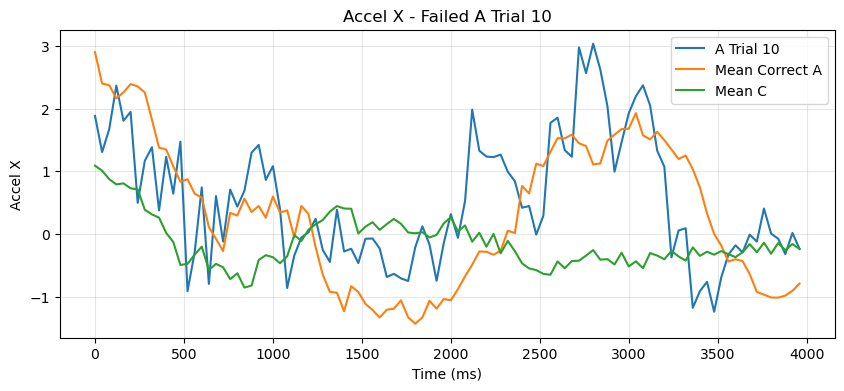

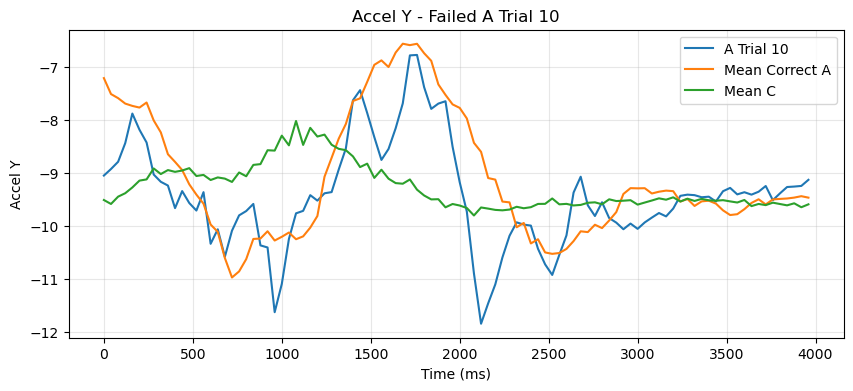

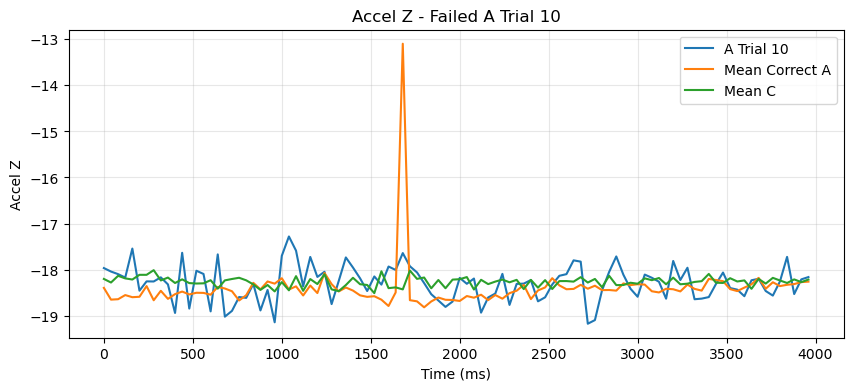

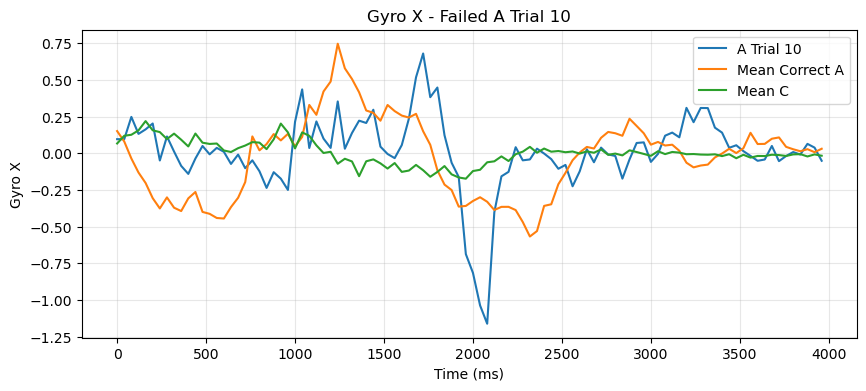

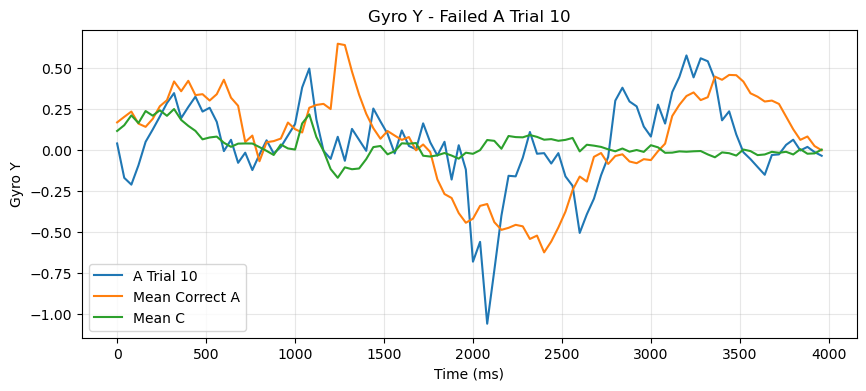

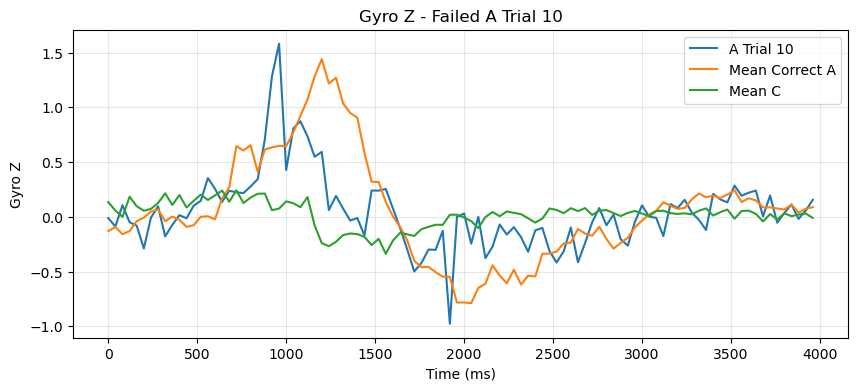

In [15]:
failed_A_trials = [2, 8, 10]

for trial in failed_A_trials:

    row_index = live_raw.index[
        (live_raw["actual"] == "A") &
        (live_raw["trial_number"] == trial)
    ][0]

    recording = sensor_array[row_index]

    for channel_index, channel_name in enumerate(channels):

        plt.figure(figsize = (10, 4))

        plt.plot(
            time_ms,
            recording[:, channel_index],
            label = f"A Trial {trial}"
        )

        plt.plot(
            time_ms,
            A_correct_mean[:, channel_index],
            label = "Mean Correct A"
        )

        plt.plot(
            time_ms,
            C_mean[:, channel_index],
            label = "Mean C"
        )

        plt.xlabel("Time (ms)")
        plt.ylabel(channel_name)

        plt.title(
            f"{channel_name} - Failed A Trial {trial}"
        )

        plt.legend()
        plt.grid(alpha = 0.3)
        plt.show()

In [16]:
importances = model.feature_importances_.reshape(
    samples_per_recording,
    len(channels)
)

channel_importance = importances.sum(axis = 0)

importance_table = pd.DataFrame({
    "channel": channels,
    "importance": channel_importance
})

importance_table["percentage"] = (
    importance_table["importance"]
    / importance_table["importance"].sum()
    * 100
)

importance_table = importance_table.sort_values(
    "importance",
    ascending = False
)

print(
    importance_table.to_string(
        index = False,
        float_format = lambda x: f"{x:.3f}"
    )
)

channel  importance  percentage
Accel X       0.314      31.358
Accel Y       0.238      23.843
 Gyro Y       0.198      19.766
 Gyro X       0.116      11.569
 Gyro Z       0.072       7.166
Accel Z       0.063       6.298


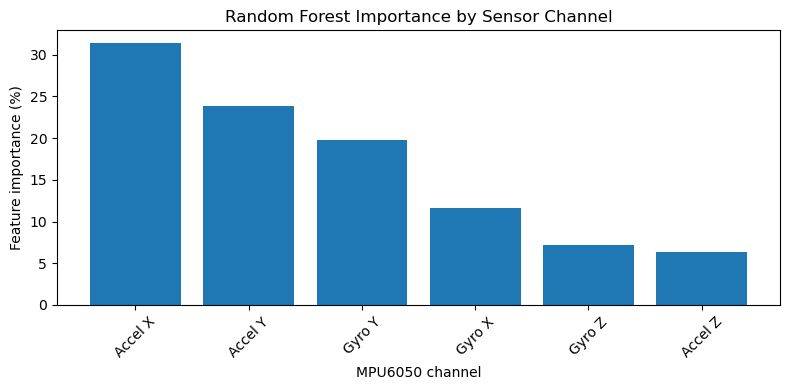

In [17]:
plt.figure(figsize = (8, 4))

plt.bar(
    importance_table["channel"],
    importance_table["percentage"]
)

plt.ylabel("Feature importance (%)")
plt.xlabel("MPU6050 channel")
plt.title("Random Forest Importance by Sensor Channel")

plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [18]:
# Checking each live recording for unusually large sample-to-sample jumps

jump_rows = []

for row_index in range(len(sensor_array)):

    recording = sensor_array[row_index]

    for channel_index, channel_name in enumerate(channels):

        values = recording[:, channel_index]

        # Difference between consecutive samples 
        jumps = np.abs(np.diff(values))

        max_jump_index = np.argmax(jumps)
        max_jump = jumps[max_jump_index]

        jump_rows.append({
            "actual": live_raw.iloc[row_index]["actual"],
            "trial": live_raw.iloc[row_index]["trial_number"],
            "predicted": live_raw.iloc[row_index]["predicted"],
            "channel": channel_name,
            "max_jump": max_jump,
            "time_ms": time_ms[max_jump_index + 1]
        })

jump_table = pd.DataFrame(jump_rows)

jump_table = jump_table.sort_values(
    "max_jump",
    ascending = False
)

print(
    jump_table.head(20).to_string(
        index = False,
        float_format = lambda x: f"{x:.3f}"
    )
)



actual  trial predicted channel  max_jump  time_ms
     A      2         C Accel Z    38.869      720
     A      9         A Accel Z    38.269     1720
     B      1         B Accel Z    37.988     2320
     C      7         C Accel X     2.744     1960
     A      4         A Accel X     2.734     2400
     A      2         C Accel X     2.665      560
     C      4         C Accel X     2.511     2040
     A      6         A Accel X     2.465      640
     A      1         A Accel X     2.429     3480
     A     10         C Accel X     2.387      520
     C      7         C Accel Z     2.273     1560
     C      5         C Accel X     2.251      480
     B      2         B Accel X     2.104     1040
     C      3         C Accel X     2.071      640
     C      4         C Accel Z     1.980      800
     A      9         A Accel X     1.896     1120
     C      1         C Accel X     1.811      920
     A      3         A Accel X     1.810      680
     B      6         B Accel X

In [19]:
required_variables = [
    "live_raw",
    "sensor_array",
    "channels",
    "A_correct_mean",
    "C_mean"
]

for variable in required_variables:
    print(
        variable,
        "FOUND" if variable in globals() else "MISSING"
    )

live_raw FOUND
sensor_array FOUND
channels FOUND
A_correct_mean FOUND
C_mean FOUND


In [20]:
import pandas as pd
import numpy as np
import joblib

# Loading live raw data
live_raw = pd.read_csv("live_test_raw_data.csv")

# Loading metadata and model
metadata = joblib.load("mpu6050_abc_metadata.pkl")
model = joblib.load("mpu6050_abc_random_forest.pkl")

# Identify the 600 sensor columns 
value_columns = [
    col for col in live_raw.columns
    if col.startswith("value_")
]

# Converting to numeric feature matrix 
X_live = live_raw[value_columns].astype(float)

# Rebuilding sensor array: 30 recordings x 100 samples x 6 channels
channels = metadata["channels_order"]
samples_per_recording = metadata["samples_per_recording"]

sensor_array = X_live.to_numpy().reshape(
    len(X_live),
    samples_per_recording,
    len(channels)
)

print("live_raw:", live_raw.shape)
print("X_live:", X_live.shape)
print("sensor_array:", sensor_array.shape)
print("channels:", channels)

live_raw: (30, 604)
X_live: (30, 600)
sensor_array: (30, 100, 6)
channels: ['Accel X', 'Accel Y', 'Accel Z', 'Gyro X', 'Gyro Y', 'Gyro Z']


In [21]:
# Recalculating predictions just to make sure everything is aligned
pred_check = model.predict(X_live.to_numpy())

# Correct A recordings
A_correct_mask = (
    (live_raw["actual"] == "A") &
    (pred_check == "A")
)

# All actual C recordings 
C_mask = live_raw["actual"] == "C"

A_correct_mean = sensor_array[A_correct_mask].mean(axis = 0)
C_mean = sensor_array[C_mask].mean(axis = 0)

print("Number of correct A recordings:", A_correct_mask.sum())
print("Number of C recordings:", C_mask.sum())

print("A_correct_mean shape:", A_correct_mean.shape)
print("C_mean shape:", C_mean.shape)



Number of correct A recordings: 7
Number of C recordings: 10
A_correct_mean shape: (100, 6)
C_mean shape: (100, 6)


In [22]:
required_variables = [
    "live_raw",
    "sensor_array",
    "channels",
    "A_correct_mean",
    "C_mean"
]

for variable in required_variables:
    print(
        variable,
        "FOUND" if variable in globals() else "MISSING"
    )

live_raw FOUND
sensor_array FOUND
channels FOUND
A_correct_mean FOUND
C_mean FOUND


In [23]:
# Comparing each A trial to the mean Correct-A and mean-C trajectories

distance_rows = []

for trial in range(1, 11):

    row_index = live_raw.index[
        (live_raw["actual"] == "A") &
        (live_raw["trial_number"] == trial)
    ][0]

    recording = sensor_array[row_index]

    # Mean absolute distance across all 100 time points and all 6 channels
    distance_to_A = np.mean(
        np.abs(recording - A_correct_mean)
    )

    distance_to_C = np.mean(
        np.abs(recording - C_mean)
    )

    predicted = live_raw.loc[row_index, "predicted"]

    distance_rows.append({
        "trial": trial,
        "predicted": predicted,
        "distance_to_correct_A": distance_to_A,
        "distance_to_C": distance_to_C,
        "closer_to": (
            "Correct A"
            if distance_to_A < distance_to_C
            else "C"
        )
    })

A_distance_table = pd.DataFrame(distance_rows)

print(
    A_distance_table.to_string(
        index = False,
        float_format = lambda x: f"{x:.4f}"
    )
)

 trial predicted  distance_to_correct_A  distance_to_C closer_to
     1         A                 0.3964         0.7439 Correct A
     2         C                 1.1571         0.8485         C
     3         A                 0.5157         0.8341 Correct A
     4         A                 0.5897         0.5792         C
     5         A                 0.4248         0.7334 Correct A
     6         A                 0.3739         0.5963 Correct A
     7         A                 0.3483         0.6408 Correct A
     8         C                 0.6110         0.5713         C
     9         A                 0.5154         0.5861 Correct A
    10         C                 0.4202         0.4411 Correct A


In [24]:
# BUILDING TIMING-ROBUST SUMMARY FEATURES FOR EACH RECORDING

def extract_summary_features(sensor_data):

    feature_rows = []

    for recording in sensor_data:

        features = []

        for channel_index in range(recording.shape[1]):

            x = recording[:, channel_index]
            dx = np.diff(x)

            features.extend([
                np.mean(x),
                np.std(x),
                np.min(x),
                np.max(x),
                np.ptp(x),                     # range
                np.sqrt(np.mean(x ** 2)),      # RMS
                np.mean(np.abs(dx)),           # average change
                np.max(np.abs(dx)),            # largest jump
                np.sum(np.abs(dx))             # total movement
            ])

        feature_rows.append(features)

    return np.array(feature_rows)



live_summary_features = extract_summary_features(sensor_array)

print("Summary feature matrix shape:",
      live_summary_features.shape)

print("Features per recording:", live_summary_features.shape[1])
            

Summary feature matrix shape: (30, 54)
Features per recording: 54


In [25]:
# CREATE LABEL VECTOR

y_live = live_raw["actual"].to_numpy()

print("Labels:", np.unique(y_live, return_counts = True))

Labels: (array(['A', 'B', 'C'], dtype=object), array([10, 10, 10]))


In [26]:
# STANDARDIZING THE 54 SUMMARY FEATURES

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

summary_scaled = scaler.fit_transform(
    live_summary_features
)

print("Scaled feature shape:", summary_scaled.shape)

Scaled feature shape: (30, 54)


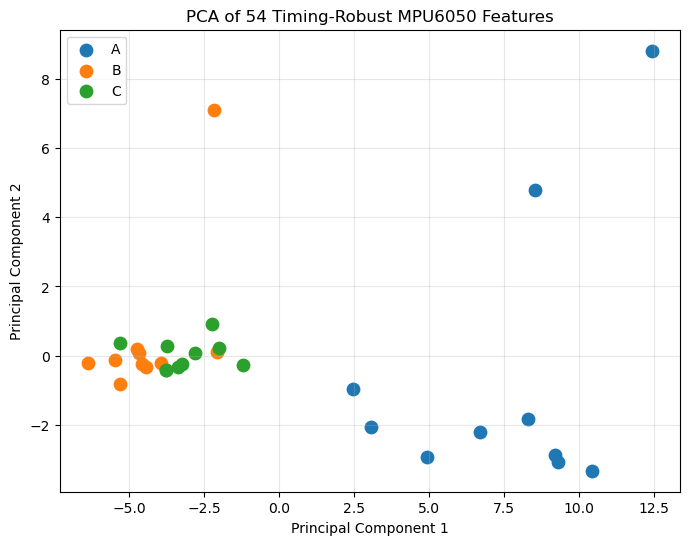

Variance explained: [0.60491479 0.12629021]
Total variance in first two PCs: 0.7312049952940165


In [27]:
# PCA VISUALIZATION OF LIVE SUMMARY FEATURES

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2)

summary_pca = pca.fit_transform(
    summary_scaled
)

plt.figure(figsize = (8, 6))

for label in ["A", "B", "C"]:

    mask = y_live == label

    plt.scatter(
        summary_pca[mask, 0],
        summary_pca[mask, 1],
        label = label,
        s = 80
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of 54 Timing-Robust MPU6050 Features")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

print(
    "Variance explained:",
    pca.explained_variance_ratio_
)

print(
    "Total variance in first two PCs:",
    pca.explained_variance_ratio_.sum()
)

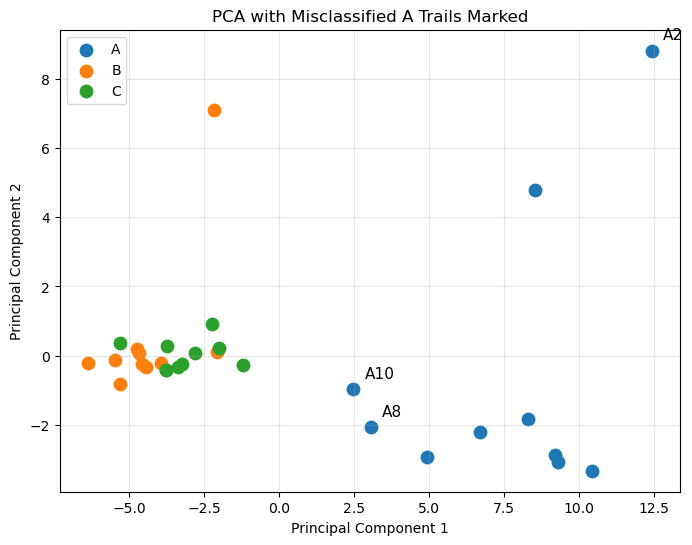

In [28]:
# DEMONSTRATE WHICH PCA POINTS ARE THE THREE FAILED A TRIALS

plt.figure(figsize = (8, 6))

for label in ["A", "B", "C"]:

    mask = y_live == label

    plt.scatter(
        summary_pca[mask, 0],
        summary_pca[mask, 1],
        label = label,
        s = 80
    )

failed_A_trials = [2, 8, 10]

for trial in failed_A_trials:

    row_index = live_raw.index[
        (live_raw["actual"] == "A") &
        (live_raw["trial_number"] == trial)
    ][0]

    plt.annotate(
        f"A{trial}",
        (
            summary_pca[row_index, 0],
            summary_pca[row_index, 1]
        ),
        xytext = (8, 8),
        textcoords = "offset points",
        fontsize = 11
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA with Misclassified A Trails Marked")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

In [29]:
# ============================================================
# CROSS-VALIDATED TEST OF THE 54 SUMMARY FEATURES
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

X_summary = live_summary_features
y_summary = live_raw["actual"].to_numpy()

loo = LeaveOneOut()

summary_rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced",
    max_features="sqrt"
)

cv_predictions = cross_val_predict(
    summary_rf,
    X_summary,
    y_summary,
    cv=loo
)

print(
    "Leave-One-Out Accuracy:",
    f"{accuracy_score(y_summary, cv_predictions):.3f}"
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_summary,
        cv_predictions,
        labels=["A", "B", "C"]
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_summary,
        cv_predictions,
        labels=["A", "B", "C"],
        digits=3
    )
)

# Show every recording and its cross-validated prediction
cv_results = live_raw[
    ["actual", "trial_number"]
].copy()

cv_results["summary_prediction"] = cv_predictions
cv_results["correct"] = (
    cv_results["actual"] ==
    cv_results["summary_prediction"]
)

print("\nIndividual predictions:")
print(cv_results.to_string(index=False))

Leave-One-Out Accuracy: 0.900

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

           A      1.000     1.000     1.000        10
           B      0.818     0.900     0.857        10
           C      0.889     0.800     0.842        10

    accuracy                          0.900        30
   macro avg      0.902     0.900     0.900        30
weighted avg      0.902     0.900     0.900        30


Individual predictions:
actual  trial_number summary_prediction  correct
     A             1                  A     True
     A             2                  A     True
     A             3                  A     True
     A             4                  A     True
     A             5                  A     True
     A             6                  A     True
     A             7                  A     True
     A             8                  A     True
     A             9                  A    

In [30]:
# CHECKING THE THREE PREVIOUSLY MISCLASSIFIED A TRIALS

print("\nPreviously failed A trials:\n")

for trial in [2, 8, 10]:

    mask = (
        (cv_results["actual"] == "A") &
        (cv_results["trial_number"] == trial)
    )

    print(
        cv_results.loc[
            mask,
            ["actual", "trial_number", "summary_prediction", "correct"]
        ].to_string(index = False)
    )    


Previously failed A trials:

actual  trial_number summary_prediction  correct
     A             2                  A     True
actual  trial_number summary_prediction  correct
     A             8                  A     True
actual  trial_number summary_prediction  correct
     A            10                  A     True


In [31]:
# FIND WHICH SUMMARY FEATURES MATTER MOST

# Names that correspond to the 9 features calculated per channel
feature_types = [
    "mean",
    "std",
    "min",
    "max",
    "range",
    "RMS",
    "avg_abs_change",
    "max_jump",
    "total_movement"
]

feature_names = []

for channel in channels:
    for feature in feature_types:
        feature_names.append(f"{channel} - {feature}")

# Train RF on all 30 recordings only for feature analysis
importance_rf = RandomForestClassifier(
    n_estimators = 1000,
    random_state = 42,
    class_weight = "balanced",
    max_features = "sqrt"
)

importance_rf.fit(
    live_summary_features,
    y_summary
)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending = False
).reset_index(drop = True)

print("Top 20 most important summary features:\n")

print(
    feature_importance.head(20).to_string(
        index = False,
        float_format = lambda x: f"{x:.4f}"
    )
)

Top 20 most important summary features:

                feature  importance
          Accel Y - max      0.0590
          Accel X - max      0.0551
          Accel X - std      0.0414
         Gyro Z - range      0.0331
          Accel Y - min      0.0319
      Gyro Z - max_jump      0.0302
         Gyro X - range      0.0301
      Gyro X - max_jump      0.0291
          Accel Y - std      0.0278
          Gyro Y - mean      0.0276
           Gyro X - min      0.0266
           Gyro X - std      0.0265
Gyro X - total_movement      0.0265
           Gyro X - max      0.0264
           Gyro Y - RMS      0.0255
           Gyro X - RMS      0.0249
           Gyro Y - std      0.0248
           Gyro Z - max      0.0245
           Gyro Z - std      0.0243
         Gyro Y - range      0.0240


In [32]:
# Importance grouped by sensor channel

feature_importance["channel"] = (
    feature_importance["feature"]
    .str.split(" - ")
    .str[0]
)

channel_importance = (
    feature_importance
    .groupby("channel")["importance"]
    .sum()
    .sort_values(ascending = False)
)

print("Total importance by sensor channel:\n")
print(channel_importance.to_string(
    float_format = lambda x: f"{x:.4f}"
))

Total importance by sensor channel:

channel
Gyro X    0.2244
Accel Y   0.2212
Accel X   0.1784
Gyro Y    0.1609
Gyro Z    0.1593
Accel Z   0.0558


In [33]:
# TESTING ONLY THE THREE MOST INFORMATIVE SENSOR CHANNELS
# Gyro X + Accel Y + Accel X

selected_channels = [
    "Gyro X",
    "Accel Y",
    "Accel X"
]

# Discover the column positions of those channels
selected_channel_indices = [
    channels.index(channel)
    for channel in selected_channels
]

# Keep only those channels from the original sensor data 
reduced_sensor_array = sensor_array[
    :, :, selected_channel_indices
]

print("Original sensor array:", sensor_array.shape)
print("Reduced sensor array:", reduced_sensor_array.shape)

# Extract the same 9 summary feature for each selected channel
reduced_summary_features = extract_summary_features(
    reduced_sensor_array
)

print(
    "Reduced summary feature matrix:",
    reduced_summary_features.shape
)

# LEAVE-ONE-OUT CROSS-VALIDATION

reduced_rf = RandomForestClassifier(
    n_estimators = 500,
    random_state = 42,
    class_weight = "balanced",
    max_features = "sqrt"
)

reduced_predictions = cross_val_predict(
    reduced_rf,
    reduced_summary_features,
    y_summary,
    cv = LeaveOneOut()
)

print(
    "\nReduced-feature Leave-One-Out Accuracy:",
    f"{accuracy_score(y_summary, reduced_predictions):.3f}"
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_summary,
        reduced_predictions,
        labels = ["A", "B", "C"]
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_summary,
        reduced_predictions,
        labels = ["A", "B", "C"],
        digits = 3
    )
)

# SHOW INDIVIDUAL RESULTS

reduced_results = live_raw[
    ["actual", "trial_number"]
].copy()

reduced_results["prediction"] = reduced_predictions

reduced_results["correct"] = (
    reduced_results["actual"]
    == reduced_results["prediction"]
)

print("\nIndividual predictions:\n")

print(
    reduced_results[
        (reduced_results["actual"] == "A") &
        (reduced_results["trial_number"].isin([2, 8, 10]))
    ].to_string(index = False)
)

Original sensor array: (30, 100, 6)
Reduced sensor array: (30, 100, 3)
Reduced summary feature matrix: (30, 27)

Reduced-feature Leave-One-Out Accuracy: 0.867

Confusion Matrix:
[[10  0  0]
 [ 0  7  3]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

           A      1.000     1.000     1.000        10
           B      0.875     0.700     0.778        10
           C      0.750     0.900     0.818        10

    accuracy                          0.867        30
   macro avg      0.875     0.867     0.865        30
weighted avg      0.875     0.867     0.865        30


Individual predictions:

actual  trial_number prediction  correct
     A             2          A     True
     A             8          A     True
     A            10          A     True


In [34]:
# COMPARE 3, 4, 5, AND 6 SENSOR CHANNEL MODELS

channel_sets = {
    "3 channels": [
        "Gyro X",
        "Accel Y",
        "Accel X"
    ],

    "4 channels": [
        "Gyro X",
        "Accel Y",
        "Accel X",
        "Gyro Y"
    ],

    "5 channels": [
        "Gyro X",
        "Accel Y",
        "Accel X",
        "Gyro Y",
        "Gyro Z"
    ],

    "6 channels": [
        "Gyro X",
        "Accel Y",
        "Accel X",
        "Gyro Y",
        "Gyro Z",
        "Accel Z"
    ]
}

comparison_rows = []

for model_name, selected_channels in channel_sets.items():

    selected_indices = [
        channels.index(channel)
        for channel in selected_channels
    ]

    selected_sensor_array = sensor_array[
        :, :, selected_indices
    ]

    selected_summary_features = extract_summary_features(
        selected_sensor_array
    )

    rf = RandomForestClassifier(
        n_estimators = 500,
        random_state = 42,
        class_weight = "balanced",
        max_features = "sqrt"
    )

    predictions = cross_val_predict(
        rf,
        selected_summary_features,
        y_summary,
        cv = LeaveOneOut()
    )

    accuracy = accuracy_score(
        y_summary,
        predictions
    )

    cm = confusion_matrix(
        y_summary,
        predictions,
        labels = ["A", "B", "C"]
    )

    A_correct = cm[0, 0]
    B_correct = cm[1, 1]
    C_correct = cm[2, 2]

    comparison_rows.append({
        "model": model_name,
        "channels_used": ", ".join(selected_channels),
        "num_channels": len(selected_channels),
        "num_features": selected_summary_features.shape[1],
        "accuracy": accuracy,
        "A_correct": A_correct,
        "B_correct": B_correct,
        "C_correct": C_correct
    })


channel_model_comparison = pd.DataFrame(
    comparison_rows
)

print(
    channel_model_comparison.to_string(
        index = False,
        float_format = lambda x: f"{x:.3f}"
    )
)

     model                                     channels_used  num_channels  num_features  accuracy  A_correct  B_correct  C_correct
3 channels                          Gyro X, Accel Y, Accel X             3            27     0.867         10          7          9
4 channels                  Gyro X, Accel Y, Accel X, Gyro Y             4            36     0.833         10          7          8
5 channels          Gyro X, Accel Y, Accel X, Gyro Y, Gyro Z             5            45     0.900         10          9          8
6 channels Gyro X, Accel Y, Accel X, Gyro Y, Gyro Z, Accel Z             6            54     0.900         10          9          8


In [35]:
# IDENTIFY THE REMAINING MISCLASSIFIED B AND C TRIALS

misclassified_summary = cv_results[
    cv_results["correct"] == False
].copy()

print("Misclassified recordings:\n")

print(
    misclassified_summary.to_string(
        index = False
    )
)

print(
    "\nTotal misclassified:",
    len(misclassified_summary)
)

Misclassified recordings:

actual  trial_number summary_prediction  correct
     B             1                  C    False
     C             7                  B    False
     C            10                  B    False

Total misclassified: 3


In [36]:
# CONSTRUCT MEAN CORRECT-B AND CORRECT-C TRAJECTORIES

# Recalculate predictions from the original 600-feature model
# Only so the masks are aligned with the current live data
pred_check = model.predict(X_live.to_numpy())

# Correct B recordings
B_correct_mask = (
    (live_raw["actual"] == "B") &
    (pred_check == "B")
)

# Correct C recordings
C_correct_mask = (
    (live_raw["actual"] == "C") &
    (pred_check == "C")
)

B_correct_mean = sensor_array[B_correct_mask].mean(axis = 0)
C_correct_mean = sensor_array[C_correct_mask].mean(axis = 0)

print("Correct B recordings:", B_correct_mask.sum())
print("Correct C recordings:", C_correct_mask.sum())

print("B_correct_mean shape:", B_correct_mean.shape)
print("C_correct_mean shape:", C_correct_mean.shape)

Correct B recordings: 10
Correct C recordings: 10
B_correct_mean shape: (100, 6)
C_correct_mean shape: (100, 6)


In [37]:
# COMPARE THE THREE FAILED B/C TRIALS

failed_trials = [
    ("B", 1),
    ("C", 7),
    ("C", 10)
]

comparison_rows = []

for actual, trial in failed_trials:

    row_index = live_raw.index[
        (live_raw["actual"] == actual) &
        (live_raw["trial_number"] == trial)
    ][0]

    recording = sensor_array[row_index]

    distance_to_B = np.mean(
        np.abs(recording - B_correct_mean)
    )

    distance_to_C = np.mean(
        np.abs(recording - C_correct_mean)
    )

    comparison_rows.append({
        "actual": actual,
        "trial": trial,
        "distance_to_B": distance_to_B,
        "distance_to_C": distance_to_C,
        "closer_to": (
            "B"
            if distance_to_B < distance_to_C
            else "C"
        )
    })

BC_distance_table = pd.DataFrame(comparison_rows)

print(
    BC_distance_table.to_string(
        index = False,
        float_format = lambda x: f"{x:.4f}"
    )
)

actual  trial  distance_to_B  distance_to_C closer_to
     B      1         0.2992         0.4357         B
     C      7         0.3498         0.2748         C
     C     10         0.3155         0.2305         C


In [40]:
# ============================================================
# B vs C DISTANCES IN THE 54-DIMENSIONAL SUMMARY-FEATURE SPACE
# ============================================================

from sklearn.preprocessing import StandardScaler

# Use the 54 summary features
X_features = live_summary_features.copy()

# Standardize because the 54 features have different scales
scaler_summary = StandardScaler()
X_scaled = scaler_summary.fit_transform(X_features)

# Use the cross-validated predictions from our summary model
correct_mask = (cv_predictions == y_summary)

# Find correctly classified B and C recordings
B_correct_indices = np.where(
    (y_summary == "B") & correct_mask
)[0]

C_correct_indices = np.where(
    (y_summary == "C") & correct_mask
)[0]

# Mean feature vector for correctly classified B and C
B_feature_mean = X_scaled[B_correct_indices].mean(axis=0)
C_feature_mean = X_scaled[C_correct_indices].mean(axis=0)

print("Correct B recordings used:", len(B_correct_indices))
print("Correct C recordings used:", len(C_correct_indices))

failed_trials = [
    ("B", 1),
    ("C", 7),
    ("C", 10)
]

feature_distance_rows = []

for actual, trial in failed_trials:

    row_index = live_raw.index[
        (live_raw["actual"] == actual) &
        (live_raw["trial_number"] == trial)
    ][0]

    recording_features = X_scaled[row_index]

    distance_to_B = np.mean(
        np.abs(recording_features - B_feature_mean)
    )

    distance_to_C = np.mean(
        np.abs(recording_features - C_feature_mean)
    )

    feature_distance_rows.append({
        "actual": actual,
        "trial": trial,
        "distance_to_B": distance_to_B,
        "distance_to_C": distance_to_C,
        "closer_to": (
            "B"
            if distance_to_B < distance_to_C
            else "C"
        ),
        "RF_prediction": cv_predictions[row_index]
    })

feature_distance_table = pd.DataFrame(feature_distance_rows)

print("\nDistances in standardized 54-feature space:\n")

print(
    feature_distance_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

Correct B recordings used: 9
Correct C recordings used: 8

Distances in standardized 54-feature space:

actual  trial  distance_to_B  distance_to_C closer_to RF_prediction
     B      1         0.7051         0.8070         B             C
     C      7         0.5670         0.4752         C             B
     C     10         0.4363         0.4305         C             B


In [39]:
# COMPARE CLASSIFIERS USING THE SAME 54 SUMMARY FEATURES

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix

X_compare = live_summary_features.copy()
y_compare = y_summary.copy()

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        random_state=42,
        class_weight="balanced",
        max_features="sqrt"
    ),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            class_weight="balanced"
        ))
    ]),

    "Linear SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="linear",
            class_weight="balanced"
        ))
    ]),

    "RBF SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            class_weight="balanced"
        ))
    ]),

    "k-NN (k=3)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=3
        ))
    ]),

    "LDA": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        ))
    ])
}

loo = LeaveOneOut()

comparison_rows = []
prediction_storage = {}

for model_name, classifier in models.items():

    predictions = cross_val_predict(
        classifier,
        X_compare,
        y_compare,
        cv=loo
    )

    prediction_storage[model_name] = predictions

    accuracy = accuracy_score(
        y_compare,
        predictions
    )

    cm = confusion_matrix(
        y_compare,
        predictions,
        labels=["A", "B", "C"]
    )

    comparison_rows.append({
        "model": model_name,
        "accuracy": accuracy,
        "correct_total": np.trace(cm),
        "A_correct": cm[0, 0],
        "B_correct": cm[1, 1],
        "C_correct": cm[2, 2]
    })

model_comparison = pd.DataFrame(
    comparison_rows
).sort_values(
    "accuracy",
    ascending=False
).reset_index(drop=True)

print("LOOCV CLASSIFIER COMPARISON:\n")

print(
    model_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


LOOCV CLASSIFIER COMPARISON:

              model  accuracy  correct_total  A_correct  B_correct  C_correct
Logistic Regression     1.000             30         10         10         10
         Linear SVM     1.000             30         10         10         10
                LDA     1.000             30         10         10         10
         k-NN (k=3)     1.000             30         10         10         10
            RBF SVM     0.967             29         10          9         10
      Random Forest     0.900             27         10          9          8


In [42]:
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Reusing the 54-feature matrix already created
X_final = live_summary_features
y_final = y_summary

# Construct final pipeline
final_logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter = 5000,
        class_weight = "balanced"
    ))
])

# Training on all 30 A/B/C recordings
final_logistic_model.fit(X_final, y_final)

print("Final model trained.")
print("Classes:", final_logistic_model.classes_)
print("Input features:", X_final.shape[1])

# Saving the trained model
joblib.dump(
    final_logistic_model,
    "mpu6050_abc_summary_logistic.pkl"
)

print("Saved: mpu6050_abc_summary_logistic.pkl")

Final model trained.
Classes: ['A' 'B' 'C']
Input features: 54
Saved: mpu6050_abc_summary_logistic.pkl


In [43]:
loaded_model = joblib.load(
    "mpu6050_abc_summary_logistic.pkl"
)

test_predictions = loaded_model.predict(
    live_summary_features
)

test_probabilities = loaded_model.predict_proba(
    live_summary_features
)

print("Reloaded model classes:", loaded_model.classes_)
print()

for i in range(len(test_predictions)):
    print(
        f"Actual: {y_summary[i]} | "
        f"Predicted: {test_predictions[i]} | "
        f"Probabilities: {test_probabilities[i]}"
    )

Reloaded model classes: ['A' 'B' 'C']

Actual: A | Predicted: A | Probabilities: [9.99291600e-01 3.82621789e-05 6.70138113e-04]
Actual: A | Predicted: A | Probabilities: [9.99737041e-01 2.61928442e-05 2.36765739e-04]
Actual: A | Predicted: A | Probabilities: [9.99874384e-01 5.84328898e-05 6.71836078e-05]
Actual: A | Predicted: A | Probabilities: [9.98652624e-01 1.05257771e-04 1.24211854e-03]
Actual: A | Predicted: A | Probabilities: [9.99291059e-01 1.86131640e-05 6.90328276e-04]
Actual: A | Predicted: A | Probabilities: [9.89212567e-01 6.15450810e-05 1.07258880e-02]
Actual: A | Predicted: A | Probabilities: [0.99269242 0.00252478 0.0047828 ]
Actual: A | Predicted: A | Probabilities: [0.97919191 0.00918304 0.01162505]
Actual: A | Predicted: A | Probabilities: [9.97058552e-01 2.66930188e-04 2.67451827e-03]
Actual: A | Predicted: A | Probabilities: [0.94376213 0.01388264 0.04235523]
Actual: B | Predicted: B | Probabilities: [0.00314135 0.97819633 0.01866232]
Actual: B | Predicted: B | Pro

In [44]:
import inspect

print(inspect.getsource(extract_summary_features))

def extract_summary_features(sensor_data):

    feature_rows = []

    for recording in sensor_data:

        features = []

        for channel_index in range(recording.shape[1]):

            x = recording[:, channel_index]
            dx = np.diff(x)

            features.extend([
                np.mean(x),
                np.std(x),
                np.min(x),
                np.max(x),
                np.ptp(x),                     # range
                np.sqrt(np.mean(x ** 2)),      # RMS
                np.mean(np.abs(dx)),           # average change
                np.max(np.abs(dx)),            # largest jump
                np.sum(np.abs(dx))             # total movement
            ])

        feature_rows.append(features)

    return np.array(feature_rows)



In [45]:
print("Channels:", channels)
print("Sensor array shape:", sensor_array.shape)
print("Summary feature shape:", live_summary_features.shape)

Channels: ['Accel X', 'Accel Y', 'Accel Z', 'Gyro X', 'Gyro Y', 'Gyro Z']
Sensor array shape: (30, 100, 6)
Summary feature shape: (30, 54)
